# 🎲 07 · Negative Sampling

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 7 of 9
> Course notes: pages 15–17 – *"Negative sampling: 1 positive + k negative"*, the sigmoid $\sigma$, *"10 × 300 = 3×10³ updates – roughly 10⁴ times faster"*, the logistic-regression derivation $\Delta a=-\eta(y'-y)x$, $\Delta b=-\eta(y'-y)$ · Mikolov et al. 2013, *Distributed Representations of Words and Phrases*

Notebook 06 showed that the full softmax is too slow: each step changes all $n$ rows of $U$. **Negative sampling** changes the *question* the network answers.

| | full softmax (notebook 06) | negative sampling |
|---|---|---|
| question | "which of the $n$ words is the neighbour of $c$?" | "is $o$ a real neighbour of $c$ – yes or no?" |
| output | one softmax over $n$ words | one **sigmoid** per word we ask about |
| words updated per step | all $n$ | the true word + $k$ random "negative" words |

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | Logistic regression and its update $\Delta a=-\eta(y'-y)x$ (notes page 17) |
| 2 | The negative-sampling error $E=-\log\sigma(u_o\cdot h)-\sum_{j}\log\sigma(-u_j\cdot h)$ |
| 3 | Its gradients: only $k+1$ rows of $U$ and 1 column of $V$ change |
| 4 | Drawing negatives from the unigram distribution raised to $3/4$ |
| 5 | Training, quality check, and the cost per step: $(k+2)\ d$ instead of $(n+1)\ d$ |
| 6 | Why the outputs no longer sum to 1 |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
import time

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
New in this notebook:

| Symbol | Meaning |
|---|---|
| $\sigma(s)=\dfrac{1}{1+e^{-s}}$ | sigmoid: turns any score $s$ into a probability between 0 and 1 |
| $k$ | number of negative samples per training pair (notes: 5–20, we use 5) |
| $j_1,\dots,j_k$ | indices of the **negative** words: random words that are (probably) *not* neighbours of $c$ |
| $f(w)$ | how often word $w$ appears as a target in the data |
| $P_n(w)$ | the "noise" distribution from which negatives are drawn: $P_n(w)\propto f(w)^{3/4}$ |
| $\ell$ | label: 1 for the true pair, 0 for a negative pair |

---
## 2 · Warm-up: logistic regression (notes page 17) 📈

Negative sampling is just many tiny logistic regressions, so we start with one.

### 2.1 · The model
One input number $x$, two parameters: weight $a$ and bias $b$. The prediction is

$$y'=\sigma(ax+b)$$

and the label is $y\in\lbrace0,1\rbrace$. The error is the **binary cross-entropy**:

$$E=-y\log y'-(1-y)\log(1-y')$$

### 2.2 · The gradient
We need one fact about the sigmoid: $\sigma'(s)=\sigma(s)\ (1-\sigma(s))$. With $s=ax+b$:

$$\frac{\partial E}{\partial s}=\Big(-\frac{y}{y'}+\frac{1-y}{1-y'}\Big)\ y'(1-y')=-y(1-y')+(1-y)\ y'=y'-y$$

Then $\partial s/\partial a=x$ and $\partial s/\partial b=1$, so (notes page 17):

$$\boxed{\Delta a=-\eta\ (y'-y)\ x,\qquad\Delta b=-\eta\ (y'-y)}$$

Same shape as the softmax result $y_k-\delta_{ok}$ of notebook 05: **prediction minus truth, times the input**.

In [2]:
def sigmoid(s):
    return 1.0 / (1.0 + np.exp(-s))


def logreg_grad(a, b, x, y):
    """Error and gradients of one logistic-regression example."""
    y_pred = sigmoid(a * x + b)
    E = -y * np.log(y_pred) - (1 - y) * np.log(1 - y_pred)
    return E, (y_pred - y) * x, (y_pred - y)

**Gradient check** on one example:

In [3]:
a, b, x, y = 0.7, -0.3, 2.0, 1
E, da, db = logreg_grad(a, b, x, y)
eps = 1e-6
da_num = (logreg_grad(a + eps, b, x, y)[0] - logreg_grad(a - eps, b, x, y)[0]) / (2 * eps)
db_num = (logreg_grad(a, b + eps, x, y)[0] - logreg_grad(a, b - eps, x, y)[0]) / (2 * eps)
print(f"dE/da: formula {da:.6f}   numerical {da_num:.6f}")
print(f"dE/db: formula {db:.6f}   numerical {db_num:.6f}")

dE/da: formula -0.499480   numerical -0.499480
dE/db: formula -0.249740   numerical -0.249740


📊 **Plot:** left, the sigmoid. Right, the binary cross-entropy as a function of the score $s$: for a positive example ($y=1$) the error falls as $s$ grows; for a negative example ($y=0$) it falls as $s$ becomes very negative.

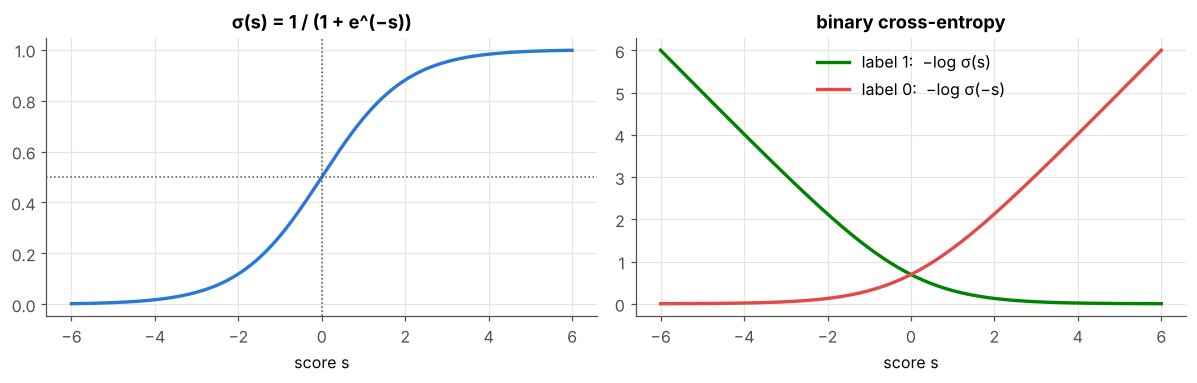

In [4]:
s = np.linspace(-6, 6, 300)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(s, sigmoid(s), color=C["blue"], lw=2.2)
axs[0].axhline(0.5, color=C["muted"], ls=":", lw=1); axs[0].axvline(0, color=C["muted"], ls=":", lw=1)
axs[0].set_title("σ(s) = 1 / (1 + e^(−s))"); axs[0].set_xlabel("score s")
axs[1].plot(s, -np.log(sigmoid(s)), color=C["green"], lw=2.2, label="label 1:  −log σ(s)")
axs[1].plot(s, -np.log(sigmoid(-s)), color=C["red"], lw=2.2, label="label 0:  −log σ(−s)")
axs[1].set_title("binary cross-entropy"); axs[1].set_xlabel("score s"); axs[1].legend()
plt.tight_layout(); plt.show()

Note $1-\sigma(s)=\sigma(-s)$: the error for a negative example can be written $-\log\sigma(-s)$. We use this below.

---
## 3 · From softmax to "yes / no" questions ✂️

For a training pair $(c,o)$ we ask $k+1$ yes/no questions, one logistic regression each, all sharing the same input $h=v_c$:

| word | score | label $\ell$ | wanted |
|---|---|---|---|
| the true neighbour $o$ | $s_o=u_o\cdot h$ | 1 | $\sigma(s_o)\to1$ |
| negative $j_1$ | $s_{j_1}=u_{j_1}\cdot h$ | 0 | $\sigma(s_{j_1})\to0$ |
| … | … | 0 | … |
| negative $j_k$ | $s_{j_k}=u_{j_k}\cdot h$ | 0 | $\sigma(s_{j_k})\to0$ |

The error is the sum of the $k+1$ binary cross-entropies:

$$E=-\log\sigma(u_o\cdot h)-\sum_{i=1}^{k}\log\sigma(-u_{j_i}\cdot h)$$

### 3.1 · The gradients
Each question is a logistic regression with input $h$ and "weight" $u_j$, so section 2.2 gives directly, for every word $j$ in the set $\lbrace o,j_1,\dots,j_k\rbrace$ with label $\ell_j$:

$$\frac{\partial E}{\partial s_j}=\sigma(s_j)-\ell_j\qquad\Rightarrow\qquad\boxed{\Delta u_j=-\eta\ \big(\sigma(u_j\cdot h)-\ell_j\big)\ h}$$

and, since $h$ appears in all $k+1$ scores,

$$\boxed{\Delta v_c=-\eta\sum_{j\in\lbrace o,j_1..j_k\rbrace}\big(\sigma(u_j\cdot h)-\ell_j\big)\ u_j}$$

**Every other row of $U$ is untouched.** Compare notebook 05: there, the push-away term $-\eta\ y_k\ h$ hit all $n$ words; here only $k$ randomly chosen words are pushed away, as a *sample* of the full sum.

### 3.2 · The update count (notes page 16)

| | rows of $U$ | values per step ($d=300$) |
|---|---|---|
| full softmax, $n=10^5$ | $10^5$ | $3\times10^7$ |
| negative sampling, $k=9$ | $k+1=10$ | $10\times300=3\times10^3$ |

That is **$10^4$ times fewer** updates per step – the notes' *"roughly $10^4$ times faster"*.

In [5]:
for n_, d_, k_ in [(75, 10, 5), (100_000, 300, 9)]:
    full, ns = n_ * d_ + d_, (k_ + 1) * d_ + d_
    print(f"n = {n_:>7,}, d = {d_}, k = {k_}:  full softmax {full:>11,}   negative sampling {ns:>6,}   ratio {full / ns:,.0f}×")

n =      75, d = 10, k = 5:  full softmax         760   negative sampling     70   ratio 11×
n = 100,000, d = 300, k = 9:  full softmax  30,000,300   negative sampling  3,300   ratio 9,091×


---
## 4 · The data 📚

Same corpus, vocabulary and skip-gram pairs (window 3) as notebook 06.

In [6]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Vocabulary and pairs:**

In [7]:
def skipgram_pairs(sentences, index, window=3):
    """All (center, context) index pairs within `window` positions."""
    pairs = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            for ctx_pos in range(max(0, pos - window), min(len(ids), pos + window + 1)):
                if ctx_pos != pos:
                    pairs.append((c, ids[ctx_pos]))
    return np.array(pairs)

sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
pairs = skipgram_pairs(sentences, index)
N = len(pairs)
print(f"n = {n} words, N = {N:,} pairs")

n = 75 words, N = 31,734 pairs


---
## 5 · Where do the negatives come from? 🎰

Negatives are random words. Which distribution?
* **uniform** – rare words (seen a handful of times) would be picked as often as *the*; most negatives would be words the model hardly knows;
* **frequency** $f(w)$ – almost every negative would be *the, i, like*; the rare words would never be pushed away;
* **word2vec's choice**: $P_n(w)\propto f(w)^{3/4}$ – in between. Raising to $3/4$ shrinks big counts more than small ones ($1000^{0.75}\approx178$, $10^{0.75}\approx5.6$).

In [8]:
freq = np.bincount(pairs[:, 1], minlength=n).astype(float)

def noise_distribution(freq, power=0.75):
    p = freq ** power
    return p / p.sum()

P_noise = noise_distribution(freq)
order = np.argsort(-freq)
print("top-5 words:", [vocab[i] for i in order[:5]])
print("their share  –  frequency:", (freq[order[:5]] / freq.sum()).round(3), "   f^0.75:", P_noise[order[:5]].round(3))

top-5 words: ['the', 'like', 'i', 'bank', 'boy']
their share  –  frequency: [0.185 0.089 0.067 0.017 0.015]    f^0.75: [0.105 0.061 0.049 0.017 0.016]


📊 **Plot:** probability of being drawn as a negative, for the three choices (words sorted by frequency). The $3/4$ power flattens the curve: frequent words are sampled less, rare words more.

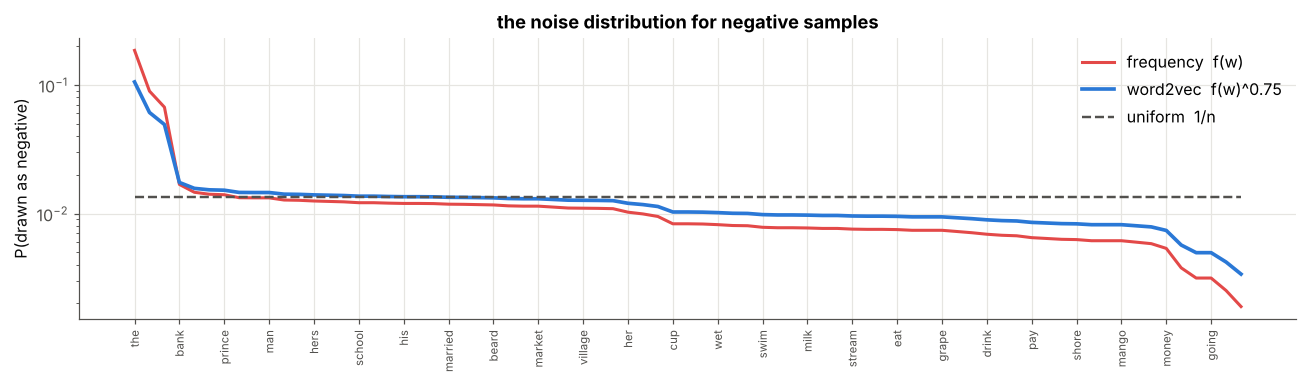

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.6))
xs = np.arange(n)
ax.plot(xs, freq[order] / freq.sum(), color=C["red"], lw=2, label="frequency  f(w)")
ax.plot(xs, P_noise[order], color=C["blue"], lw=2.4, label="word2vec  f(w)^0.75")
ax.plot(xs, np.full(n, 1 / n), color=C["muted"], lw=1.6, ls="--", label="uniform  1/n")
ax.set_xticks(xs[::3], [vocab[i] for i in order[::3]], rotation=90, fontsize=7.5)
ax.set_ylabel("P(drawn as negative)"); ax.set_yscale("log"); ax.legend()
ax.set_title("the noise distribution for negative samples")
plt.tight_layout(); plt.show()

**Drawing negatives in bulk.** Calling the random generator once per step is slow in Python, so at the start of each epoch we draw all $N\times k$ negatives at once. (Occasionally a negative equals the true word $o$; word2vec simply ignores this, and so do we.)

In [10]:
def draw_negatives(rng, n_pairs, k, P_noise):
    return rng.choice(len(P_noise), size=(n_pairs, k), p=P_noise)

demo = draw_negatives(np.random.default_rng(0), 3, 5, P_noise)
for (c, o), neg in zip(pairs[:3], demo):
    print(f"pair ({vocab[c]} → {vocab[o]})   negatives: {[vocab[j] for j in neg]}")

pair (i → like)   negatives: ['princess', 'hers', 'bank', 'apple', 'the']
pair (i → the)   negatives: ['throne', 'plays', 'shore', 'money', 'tree']
pair (i → money)   negatives: ['the', 'account', 'the', 'bank', 'shore']


---
## 6 · The model, one piece at a time 🧱

### 6.1 · Parameters
Exactly the same $V$ and $U$ as before – negative sampling changes the **training**, not the network.

In [11]:
class SkipGramNS:
    """Skip-gram word2vec trained with negative sampling."""

    def __init__(self, n, d, k=5, seed=0):
        rng = np.random.default_rng(seed)
        self.n, self.d, self.k = n, d, k
        self.V = rng.normal(0, 0.1, (d, n))
        self.U = rng.normal(0, 0.1, (n, d))
        self.steps = 0
        self.values_updated = 0

### 6.2 · One SGD step on one pair plus its negatives
| code | formula |
|---|---|
| `ids = [o, j1..jk]`, `labels = [1, 0..0]` | the $k+1$ questions |
| `s = sigmoid(U[ids] @ h)` | $\sigma(u_j\cdot h)$ – only $k+1$ dot products, no sum over $n$ |
| `g = s - labels` | $\partial E/\partial s_j=\sigma(s_j)-\ell_j$ |
| `grad_h = g @ U[ids]` | $\sum_jg_j\ u_j$ |
| `np.subtract.at(U, ids, eta * np.outer(g, h))` | $\Delta u_j$ for the $k+1$ rows only |
| `V[:, c] -= eta * grad_h` | $\Delta v_c$ |

`np.subtract.at` is used instead of `U[ids] -= …` so that a word drawn twice gets both updates.

In [12]:
def sgd_step(self, c, o, negatives, eta):
    h = self.V[:, c].copy()
    ids = np.concatenate(([o], negatives))
    labels = np.zeros(len(ids)); labels[0] = 1.0
    s = sigmoid(self.U[ids] @ h)
    E = -np.log(s[0]) - np.log(1.0 - s[1:]).sum()
    g = s - labels                              # dE/ds_j
    grad_h = g @ self.U[ids]                    # dE/dv_c
    np.subtract.at(self.U, ids, eta * np.outer(g, h))   # only k+1 rows of U
    self.V[:, c] -= eta * grad_h                # one column of V
    self.steps += 1
    self.values_updated += len(ids) * self.d + self.d
    return E

SkipGramNS.sgd_step = sgd_step

### 6.3 · One epoch
Shuffle the pairs, draw the negatives for the whole epoch, then step through them.

In [13]:
def train_epoch(self, pairs, eta, rng, P_noise, log_every=2000):
    perm = rng.permutation(len(pairs))
    negatives = draw_negatives(rng, len(pairs), self.k, P_noise)
    curve, running = [], []
    for (c, o), neg in zip(pairs[perm], negatives):
        running.append(self.sgd_step(c, o, neg, eta))
        if len(running) == log_every:
            curve.append(np.mean(running)); running = []
    return curve

SkipGramNS.train_epoch = train_epoch

### 6.4 · Reading the model
`vectors()` is the same as in notebook 06. `yes_probabilities(word)` returns $\sigma(u_k\cdot h)$ for **every** word $k$ – "how sure is the model that $w_k$ is a neighbour of this word?".

In [14]:
def vectors(self):
    return self.V / np.linalg.norm(self.V, axis=0, keepdims=True)


def yes_probabilities(self, word):
    return sigmoid(self.U @ self.V[:, index[word]])

SkipGramNS.vectors = vectors
SkipGramNS.yes_probabilities = yes_probabilities

---
## 7 · Training 🏋️

$d=10$, $k=5$, $\eta=0.05$, 5 epochs – the same budget as notebook 06.

In [15]:
d, k, eta, epochs = 10, 5, 0.05, 5
model = SkipGramNS(n, d, k=k, seed=0)
rng = np.random.default_rng(1)
curve, epoch_times = [], []
for ep in range(epochs):
    t0 = time.perf_counter()
    curve += model.train_epoch(pairs, eta, rng, P_noise)
    epoch_times.append(time.perf_counter() - t0)
    print(f"epoch {ep + 1}:  mean loss (last 2000 pairs) = {curve[-1]:.3f}   time = {epoch_times[-1]:.2f} s")
print(f"\n{model.steps:,} SGD steps, {model.values_updated:,} parameter values updated in total")

epoch 1:  mean loss (last 2000 pairs) = 2.112   time = 0.86 s
epoch 2:  mean loss (last 2000 pairs) = 2.004   time = 0.81 s
epoch 3:  mean loss (last 2000 pairs) = 2.014   time = 0.68 s
epoch 4:  mean loss (last 2000 pairs) = 1.960   time = 0.71 s
epoch 5:  mean loss (last 2000 pairs) = 2.028   time = 0.84 s

158,670 SGD steps, 11,106,900 parameter values updated in total


At the start every $\sigma\approx0.5$, so $E\approx(k+1)\log2=6\times0.693\approx4.16$. Note: this is a **different error** from notebook 06 (a sum of $k+1$ binary cross-entropies, not $-\log y_o$), so the two loss values cannot be compared directly.

📊 **Plot:** the negative-sampling loss during training.

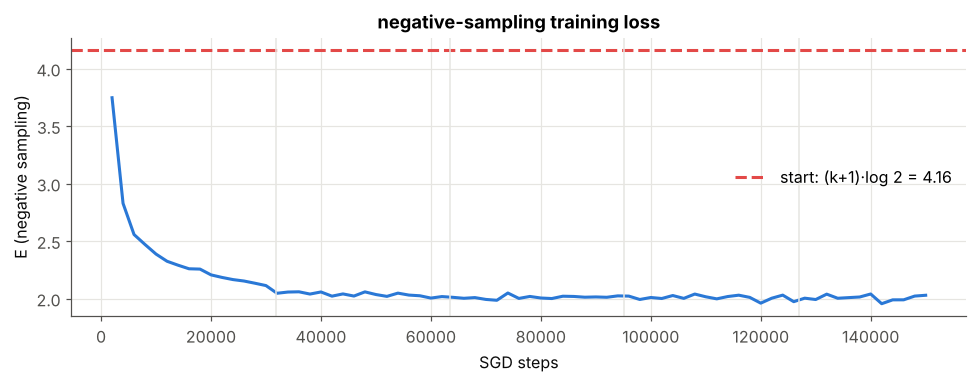

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(np.arange(1, len(curve) + 1) * 2000, curve, color=C["blue"], lw=2)
ax.axhline((k + 1) * np.log(2), color=C["red"], ls="--", label=f"start: (k+1)·log 2 = {(k + 1) * np.log(2):.2f}")
for ep in range(1, epochs):
    ax.axvline(ep * N, color=C["grid"], lw=1)
ax.set_xlabel("SGD steps"); ax.set_ylabel("E (negative sampling)"); ax.legend()
ax.set_title("negative-sampling training loss")
plt.tight_layout(); plt.show()

---
## 8 · Are the vectors still good? ✅

### 8.1 · Nearest neighbours

In [17]:
W = model.vectors()

def neighbours(word, k=5):
    sims = W.T @ W[:, index[word]]
    best = [i for i in np.argsort(-sims) if i != index[word]][:k]
    return [(vocab[i], round(float(sims[i]), 2)) for i in best]

for w in ["king", "girl", "mango", "tea", "loan", "river", "bank", "he"]:
    print(f"{w:>6} → {neighbours(w)}")

  king → [('prince', 0.76), ('man', 0.62), ('school', 0.58), ('market', 0.57), ('small', 0.56)]
  girl → [('woman', 0.75), ('princess', 0.61), ('throne', 0.6), ('farm', 0.6), ('kingdom', 0.59)]
 mango → [('banana', 0.99), ('apple', 0.98), ('grape', 0.98), ('tree', 0.82), ('juicy', 0.81)]
   tea → [('coffee', 0.99), ('milk', 0.98), ('water', 0.97), ('glass', 0.79), ('hot', 0.78)]
  loan → [('account', 0.99), ('interest', 0.99), ('money', 0.98), ('rupees', 0.77), ('apple', 0.75)]
 river → [('boat', 0.99), ('stream', 0.98), ('fish', 0.98), ('wet', 0.84), ('swim', 0.82)]
  bank → [('shore', 0.79), ('rupees', 0.78), ('pay', 0.77), ('save', 0.77), ('flow', 0.77)]
    he → [('his', 0.99), ('beard', 0.97), ('him', 0.97), ('woman', 0.6), ('prince', 0.55)]


### 8.2 · Analogies

In [18]:
def analogy(a, b, c, k=3):
    q = W[:, index[a]] - W[:, index[b]] + W[:, index[c]]
    sims = W.T @ (q / np.linalg.norm(q))
    for w in (a, b, c):
        sims[index[w]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]

tests = [("king", "man", "woman", "queen"), ("prince", "boy", "girl", "princess"), ("queen", "woman", "man", "king"),
         ("man", "boy", "princess", "queen"), ("girl", "woman", "king", "prince")]
for a, b, c, want in tests:
    got = analogy(a, b, c)
    print(f"{a} − {b} + {c} = {got}   {'✅' if got[0] == want else '❌'} (expected {want})")

king − man + woman = ['queen', 'princess', 'beard']   ✅ (expected queen)
prince − boy + girl = ['princess', 'queen', 'hers']   ✅ (expected princess)
queen − woman + man = ['king', 'prince', 'market']   ✅ (expected king)
man − boy + princess = ['queen', 'woman', 'hers']   ✅ (expected queen)
girl − woman + king = ['prince', 'boy', 'market']   ✅ (expected prince)


### 8.3 · A 2-D map
Same PCA projection as notebook 06.

In [19]:
# ---------- plotting helper (visualisation only) ----------
GROUPS = {"royal person": ([w for w, a in PEOPLE.items() if a[0] == "royal"], C["violet"]),
          "common person": ([w for w, a in PEOPLE.items() if a[0] == "common"], C["magenta"]),
          "fruit": (THINGS["fruit"][0], C["orange"]), "drink": (THINGS["drink"][0], C["blue"]),
          "money": (THINGS["money"][0], C["green"]), "river": (THINGS["river"][0], C["aqua"]),
          "the word 'bank'": (["bank"], C["red"])}

def pca_2d(X):
    Xc = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T


def plot_groups(ax, W, title):
    words = [w for ws, _ in GROUPS.values() for w in ws]
    P = dict(zip(words, pca_2d(W[:, [index[w] for w in words]].T)))
    for label, (ws, col) in GROUPS.items():
        pts = np.array([P[w] for w in ws])
        ax.scatter(pts[:, 0], pts[:, 1], color=col, s=50, label=label, zorder=3)
        for w in ws:
            ax.annotate(w, P[w], textcoords="offset points", xytext=(5, 3), fontsize=8.5, color=col)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

📊 **Plot:** people and things in the learned space. The same groups as with the full softmax appear.

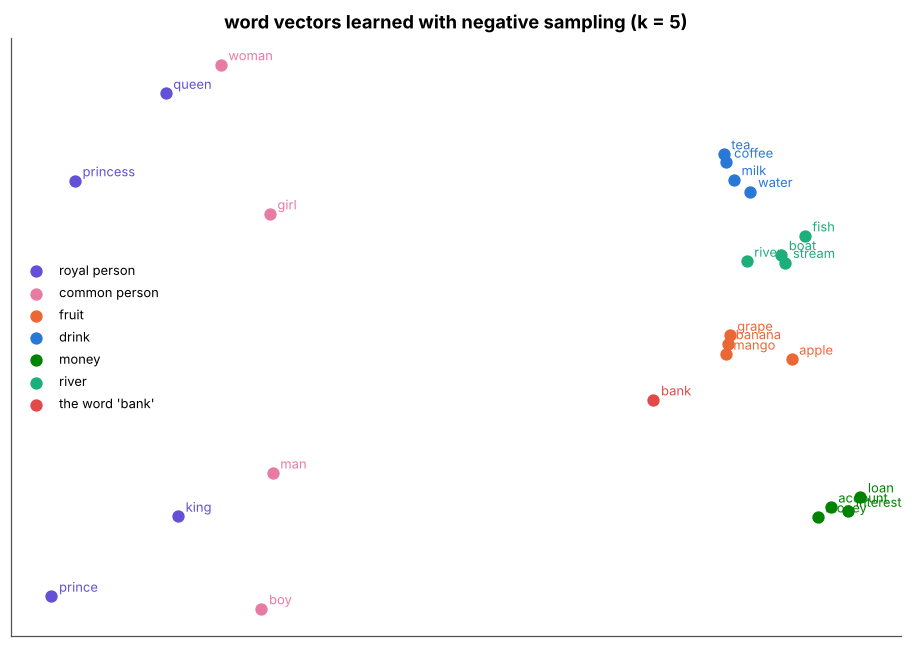

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 6))
plot_groups(ax, W, "word vectors learned with negative sampling (k = 5)")
ax.legend(fontsize=8.5, loc="best")
plt.tight_layout(); plt.show()

---
## 9 · The outputs no longer sum to 1 ⚠️

With the softmax, $\sum_ky_k=1$ by construction. Here each word has its own independent sigmoid, and nothing ties them together (notes: *"outputs may not sum to 1"*). The network no longer gives a probability distribution over the vocabulary – it only answers "is this a plausible neighbour?" for each word separately.

In [21]:
for w in ["king", "mango", "the"]:
    p = model.yes_probabilities(w)
    top = np.argsort(-p)[:5]
    print(f"{w:>6}:  Σ_k σ(u_k·h) = {p.sum():6.2f}    most likely neighbours: {[(vocab[i], round(float(p[i]), 2)) for i in top]}")

  king:  Σ_k σ(u_k·h) =   7.09    most likely neighbours: [('crown', 0.69), ('him', 0.63), ('tax', 0.59), ('his', 0.56), ('office', 0.55)]
 mango:  Σ_k σ(u_k·h) =   4.10    most likely neighbours: [('ripe', 0.82), ('sweet', 0.58), ('eat', 0.53), ('i', 0.46), ('tree', 0.42)]
   the:  Σ_k σ(u_k·h) =  11.26    most likely neighbours: [('king', 0.45), ('i', 0.37), ('bank', 0.33), ('queen', 0.32), ('wet', 0.25)]


📊 **Plot:** the "yes" probabilities $\sigma(u_k\cdot h)$ for *king*, over the whole vocabulary. Several words are close to 1 at the same time, and the total is far from 1.

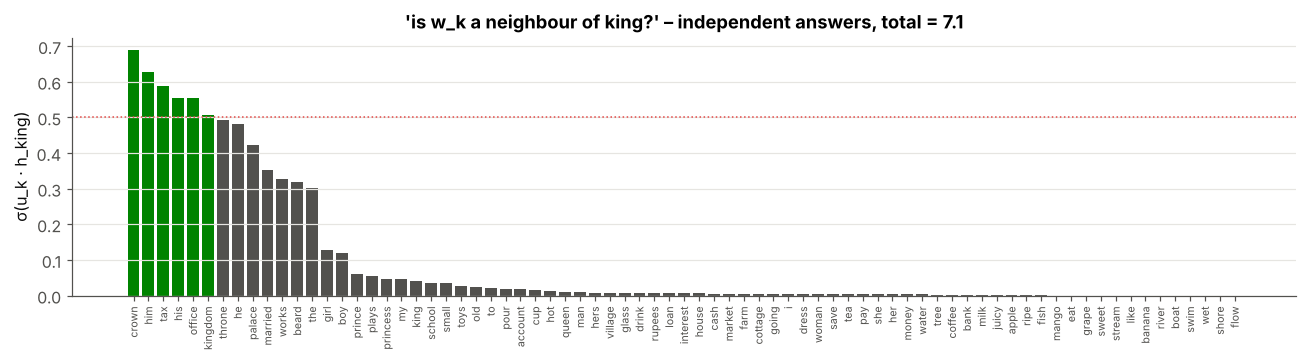

In [22]:
p = model.yes_probabilities("king")
order_p = np.argsort(-p)
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(range(n), p[order_p], color=[C["green"] if p_ > 0.5 else C["muted"] for p_ in p[order_p]], width=0.8)
ax.set_xticks(range(n), [vocab[i] for i in order_p], rotation=90, fontsize=7)
ax.axhline(0.5, color=C["red"], ls=":", lw=1)
ax.set_ylabel("σ(u_k · h_king)"); ax.grid(axis="x", visible=False)
ax.set_title(f"'is w_k a neighbour of king?' – independent answers, total = {p.sum():.1f}")
plt.tight_layout(); plt.show()

---
## 10 · The speed-up ⏱️

### 10.1 · Updates per step
Our training counted the values changed:

In [23]:
full_per_step = n * d + d
ns_per_step = model.values_updated / model.steps
print(f"full softmax      : {full_per_step:,} values per step")
print(f"negative sampling : {ns_per_step:,.0f} values per step   ((k+2)·d = {(k + 2) * d})")

full softmax      : 760 values per step
negative sampling : 70 values per step   ((k+2)·d = 70)


With only 75 words the saving is small (760 vs 70), and in Python the per-step overhead (function calls, indexing) dominates, so wall-clock time per epoch is no better than in notebook 06 (even a little worse: drawing negatives and `np.subtract.at` have their own cost). The real difference appears as $n$ grows.

### 10.2 · Time per step vs vocabulary size
Same measurement as notebook 06, $d=100$, for both methods.

In [24]:
def time_full(n_vocab, d=100, repeats=30):
    r = np.random.default_rng(0)
    V_, U_ = r.normal(0, 0.1, (d, n_vocab)), r.normal(0, 0.1, (n_vocab, d))
    t0 = time.perf_counter()
    for c, o in zip(r.integers(0, n_vocab, repeats), r.integers(0, n_vocab, repeats)):
        h = V_[:, c].copy(); z = U_ @ h; y = np.exp(z - z.max()); y /= y.sum()
        e = y; e[o] -= 1; gh = U_.T @ e; U_ -= 0.01 * np.outer(e, h); V_[:, c] -= 0.01 * gh
    return (time.perf_counter() - t0) / repeats


def time_ns(n_vocab, d=100, k=5, repeats=300):
    m = SkipGramNS(n_vocab, d, k=k)
    r = np.random.default_rng(0)
    cs, os_ = r.integers(0, n_vocab, repeats), r.integers(0, n_vocab, repeats)
    negs = r.integers(0, n_vocab, (repeats, k))
    t0 = time.perf_counter()
    for c, o, ng in zip(cs, os_, negs):
        m.sgd_step(c, o, ng, 0.01)
    return (time.perf_counter() - t0) / repeats

vocab_sizes = [100, 1_000, 10_000, 50_000, 100_000]
t_full = [time_full(nv) for nv in vocab_sizes]
t_ns = [time_ns(nv) for nv in vocab_sizes]
for nv, a, b in zip(vocab_sizes, t_full, t_ns):
    print(f"n = {nv:>7,}:  full {a * 1e3:8.3f} ms   negative sampling {b * 1e3:6.3f} ms   speed-up {a / b:7.1f}×")

n =     100:  full    0.039 ms   negative sampling  0.045 ms   speed-up     0.9×
n =   1,000:  full    0.303 ms   negative sampling  0.045 ms   speed-up     6.7×
n =  10,000:  full    5.918 ms   negative sampling  0.046 ms   speed-up   128.7×
n =  50,000:  full   37.445 ms   negative sampling  0.063 ms   speed-up   598.0×
n = 100,000:  full   79.228 ms   negative sampling  0.027 ms   speed-up  2931.8×


📊 **Plot:** full softmax grows linearly with $n$; negative sampling stays flat – its cost depends on $k$ and $d$, not on the vocabulary.

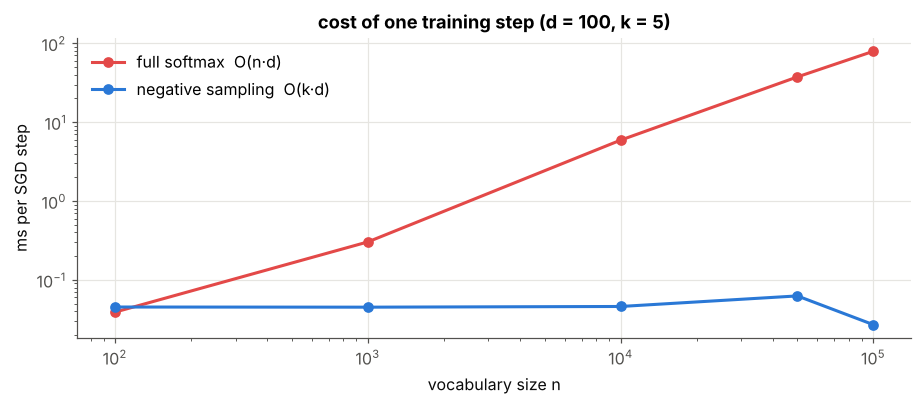

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(vocab_sizes, np.array(t_full) * 1e3, "o-", color=C["red"], lw=2, label="full softmax  O(n·d)")
ax.plot(vocab_sizes, np.array(t_ns) * 1e3, "o-", color=C["blue"], lw=2, label="negative sampling  O(k·d)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("vocabulary size n"); ax.set_ylabel("ms per SGD step"); ax.legend()
ax.set_title("cost of one training step (d = 100, k = 5)")
plt.tight_layout(); plt.show()

---
## 11 · Summary 📌

| | full softmax | negative sampling |
|---|---|---|
| question per pair | which of $n$ words? | $k+1$ yes/no questions |
| error | $-\log y_o$ | $-\log\sigma(u_o\cdot h)-\sum_j\log\sigma(-u_j\cdot h)$ |
| rows of $U$ updated | $n$ | $k+1$ |
| values per step | $(n+1)\ d$ | $(k+2)\ d$ |
| outputs sum to 1? | yes | **no** |
| word vectors | good | similar quality (all analogies still correct) |

**Key idea:** the push-away term of the softmax gradient, $-\eta\ y_k\ h$ for all $n$ words, is replaced by a **random sample** of $k$ words – the budget is fixed at **training time** (notes: *"budget at training time → negative sampling"*).

### ✍️ Try it yourself
1. Train with uniform negatives ($P_n(w)=1/n$) and with plain frequency. Which analogies break?
2. Try $k=1$ and $k=20$. How do the vectors and the time per epoch change?
3. Show that with $k=n-1$ and all words used as negatives, the update of $v_c$ looks like notebook 05's $u_o-\sum_iy_iu_i$, but with $\sigma$ instead of the softmax.
4. Why does word2vec often **subsample** very frequent words (drop *the* with some probability) in addition?

**Next →** `08 - Hierarchical Softmax`: keep a real probability distribution, but compute it in $\log_2n$ steps.